 ================================================================================================================================================================================================

 NOTEBOOK 04 — ZHU GUARDED LWC RETRIEVAL (CLEANED)

 ================================================================================================================================================================================================



 Pipeline: load data -> 30 s time-average DWR -> dDWR/dH diagnostic ->

 Zhu **guarded** retrieval -> LWC quality checks -> LWP (3 checks only, for later comparison)



 Removed in this cleanup (all still recoverable from notebook history if needed):

   - 60 s time-averaging branch

   - Raw / un-averaged Zhu retrieval exploration (superseded by the 30 s branch, which is

     what feeds the guarded retrieval anyway)

   - Most LWP diagnostics — kept only: general LWP time series, LWP closure scatter,

     and the "spot check three profiles" comparison

   - 500-1500 m windowed retrieval experiment

   - common_mask (C1/C2) redundant second retrieval pass

 ================================================================================================================================================================================================

 ## 0. Setup

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

sys.path.append(str(Path("../src").resolve()))

# Preprocessing
from radar_lwc.preprocessing.align import align_to_reference_time
from radar_lwc.preprocessing.chirps import combine_chirps
from radar_lwc.preprocessing.clean import drop_duplicate_times
from radar_lwc.preprocessing.get_reflectivity import get_reflectivity

# Retrieval
from radar_lwc.retrieval.average_ze_time import avg_ze_time
from radar_lwc.retrieval.ddwr_dh import compute_ddwr_dh
from radar_lwc.retrieval.dielectric import epsilon_water_liebe1989
from radar_lwc.retrieval.kappa_liquid import kappa_liquid
from radar_lwc.retrieval.zhu import retrieve_lwc_zhu


In [3]:
def nan_gaps(da, dim="Time", factor=5):
    """For PLOTS only: insert NaN profiles at both edges of every time gap longer than
    `factor` x the median time step (radar scanning), so pcolormesh and line plots leave
    the gap empty instead of stretching the neighbouring profiles. Data are unchanged."""
    da = da.astype(float)
    t = da[dim].values
    dt = np.median(np.diff(t))
    gaps = np.flatnonzero(np.diff(t) > factor * dt)
    if gaps.size == 0:
        return da
    new_t = np.concatenate([t[gaps] + dt, t[gaps + 1] - dt])
    filler = xr.full_like(da.isel({dim: np.r_[gaps, gaps + 1]}), np.nan).assign_coords({dim: new_t})
    return xr.concat([da, filler], dim=dim).sortby(dim)

In [4]:
Processed_Dataset = "20261002_pallas_interpolation_CLARA"

In [5]:
in_path = Path(f"../data/processed/{Processed_Dataset}/retrieval_input_4km_alpha_kappa_calculated.nc")
ds_retrieval = xr.open_dataset(in_path)
print(ds_retrieval)


<xarray.Dataset> Size: 200MB
Dimensions:          (Time: 9899, range: 237)
Coordinates:
  * Time             (Time) datetime64[ns] 79kB 2026-10-02T03:30:00.852298736...
  * range            (range) float64 2kB 104.3 119.3 ... 3.952e+03 3.986e+03
Data variables: (12/16)
    Ze_W             (Time, range) float64 19MB ...
    Ze_Ka            (Time, range) float64 19MB ...
    T_cloud          (Time, range) float64 19MB ...
    LWP              (Time) float32 40kB ...
    DWR              (Time, range) float64 19MB ...
    cloud_mask       (Time, range) bool 2MB ...
    ...               ...
    alpha_W          (Time, range) float64 19MB ...
    alpha_Ka         (Time, range) float64 19MB ...
    kappa_W          (Time, range) float64 19MB ...
    kappa_Ka         (Time, range) float64 19MB ...
    MeanVel_W        (Time, range) float64 19MB ...
    MeanVel_Ka       (Time, range) float64 19MB ...
Attributes:
    description:  Prepared inputs for Zhu et al. (2019) LWC retrieval with al..

 ================================================================================================================================================================================================

 ## 1. Time averaging (30 s only)



 Averaging Ze in linear space before forming DWR beats down per-gate DWR noise, which is a

 prerequisite for a physically meaningful dDWR/dH gradient. 30 s was kept as the working

 resolution; 60 s is dropped for now (barely changed the diagnostics — restore quickly by

 copying the `window_s=60` block back in if a comparison is ever needed again).

 ================================================================================================================================================================================================

In [6]:
for name in ("Ze_Ka", "Ze_W"):
    z = ds_retrieval[name].sel(range=slice(0, 4000)).values
    fin = z[np.isfinite(z)]
    print(f"{name}: NaN {100*np.isnan(z).mean():.1f} % | -inf {100*np.isneginf(z).mean():.2f} % | "
          f"exactly 0 dBZ {100*(z == 0).mean():.2f} % | min finite {fin.min():.1f} dBZ")

Ze_Ka: NaN 86.0 % | -inf 0.00 % | exactly 0 dBZ 0.00 % | min finite -45.0 dBZ
Ze_W: NaN 85.6 % | -inf 0.00 % | exactly 0 dBZ 0.00 % | min finite -50.0 dBZ


In [7]:
m  = ds_retrieval["common_mask"].sel(range=slice(0, 4000)).fillna(0).astype(bool)
ka = ds_retrieval["Ze_Ka"].sel(range=slice(0, 4000))
w  = ds_retrieval["Ze_W"].sel(range=slice(0, 4000))
dwr_old = avg_ze_time(ka, 30) - avg_ze_time(w, 30)                     # as now
dwr_new = avg_ze_time(ka.where(m), 30) - avg_ze_time(w.where(m), 30)   # same profiles for both
d = abs(dwr_old - dwr_new).where(m)
print(f"DWR change at cloud gates: median {float(d.median()):.3f} dB, 95th pct {float(d.quantile(0.95)):.2f} dB, "
      f"gates changed > 0.1 dB: {100*float((d > 0.1).sum() / m.sum()):.1f} %")

DWR change at cloud gates: median 0.000 dB, 95th pct 0.00 dB, gates changed > 0.1 dB: 3.5 %


In [8]:
m = ds_retrieval["common_mask"].fillna(0).astype(bool)      # same profiles for both radars
ze_ka_avg = avg_ze_time(ds_retrieval["Ze_Ka"].where(m).sel(range=slice(0, 4000)), window_s=30)
ze_w_avg  = avg_ze_time(ds_retrieval["Ze_W"].where(m).sel(range=slice(0, 4000)),  window_s=30)

dwr_2km_smoothed = ze_ka_avg - ze_w_avg
dwr_2km_smoothed.name = "DWR"


In [9]:
# %% 1 dB gate-to-gate filter (Socuellamos): replace spikes by linear interpolation
gate_threshold = 1.0  # dB

def despike_1d(dwr_1d, threshold=1.0):
    """
    dwr_1d: 1D array along range for a single time step.
    A gate i is an outlier if it differs from BOTH neighbours by more than
    `threshold` dB in the same direction (i.e. it's a spike relative to a
    smooth profile) -> replaced by linear interpolation between i-1 and i+1.
    """
    out = dwr_1d.copy()
    n = len(dwr_1d)
    for i in range(1, n - 1):
        left = dwr_1d[i] - dwr_1d[i - 1]
        right = dwr_1d[i] - dwr_1d[i + 1]
        is_spike = (
            np.abs(left) > threshold
            and np.abs(right) > threshold
            and np.sign(left) == np.sign(right)   # same direction on both sides
        )
        if is_spike and not (np.isnan(dwr_1d[i - 1]) or np.isnan(dwr_1d[i + 1]) or np.isnan(dwr_1d[i])):
            out[i] = dwr_1d[i - 1] + (dwr_1d[i + 1] - dwr_1d[i - 1]) * 0.5  # linear interp
    return out

dwr_2km_filt = xr.apply_ufunc(
    despike_1d,
    dwr_2km_smoothed,
    input_core_dims=[["range"]],
    output_core_dims=[["range"]],
    kwargs={"threshold": gate_threshold},
    vectorize=True,
)
dwr_2km_filt.name = "DWR"
dwr_2km_filt.attrs = dwr_2km_smoothed.attrs

n_replaced = int((np.abs(dwr_2km_filt - dwr_2km_smoothed) > 1e-9).sum())
print(f"Gates replaced by interpolation: {n_replaced} "
      f"({n_replaced / dwr_2km_smoothed.size:.2%} of all gates)")

Gates replaced by interpolation: 1468 (0.06% of all gates)


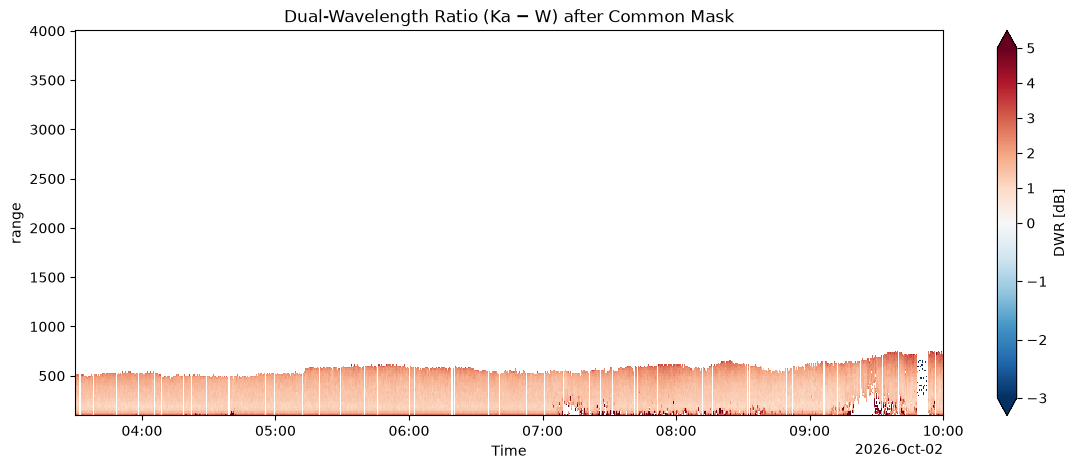

In [10]:
from matplotlib.colors import TwoSlopeNorm

fig, ax = plt.subplots(figsize=(14, 5))

nan_gaps(dwr_2km_filt.where(ds_retrieval["common_mask"])).plot(
    x="Time",
    y="range",
    cmap="RdBu_r",
    norm=TwoSlopeNorm(vmin=-3, vcenter=0, vmax=5),
    ax=ax,
    cbar_kwargs={"label": "DWR [dB]"}
)

ax.set_title("Dual-Wavelength Ratio (Ka − W) after Common Mask")
plt.show()

 ================================================================================================================================================================================================

 ## 3. Zhu Guarded retrieval



 Drop-in replacement for the plain gradient retrieval: overlap-averages the window fit and

 rejects windows that are too noisy (`max_window_std`) or produce an unphysical gradient

 (`max_ddwr_dh`), with `edge_pad` gates skipped near cloud base/top.

 ================================================================================================================================================================================================

In [11]:
N_DEFAULT = 13

lwc_guarded, derivative_guarded, m_eff, n_windows, n_used= retrieve_lwc_zhu( 
    dwr=dwr_2km_filt,
    kappa_w=ds_retrieval["kappa_W"],
    kappa_ka=ds_retrieval["kappa_Ka"],
    alpha_w=ds_retrieval["alpha_W"],
    alpha_ka=ds_retrieval["alpha_Ka"],
    cloud_mask=ds_retrieval["common_mask"],
    N_default=N_DEFAULT,
    min_cloud_gates=3,
    max_ddwr_dh=30.0,
    max_window_std=1,
    edge_pad_bottom=2,         # was edge_pad=0
    edge_pad_top=1,
)

print(f"Gates with any retrieval: {int((n_windows > 0).sum())} "
      f"({100*float((n_windows>0).mean()):.1f}%)")
print(f"Mean windows per gate:    {float(n_windows.where(n_windows>0).mean()):.1f}")


Gates with any retrieval: 274724 (11.7%)
Mean windows per gate:    7.4


## Interior vs Outer edges Noise

In [12]:
# Edge-gate noise: std of adjacent-gate DWR differences, by pair position from cloud base / top
TR   = lambda a: a.transpose("Time", "range")
dwr  = TR(dwr_2km_filt)
msk  = TR(ds_retrieval["common_mask"]).reindex_like(dwr).fillna(0).astype(bool)   # same grid as dwr
x    = np.where(msk.values, dwr.values, np.nan)
d    = np.diff(x, axis=1)                         # pair k = gates (k, k+1); NaN if either is outside cloud

MAX_POS = 6                                       # pairs counted from each edge
from_base = [[] for _ in range(MAX_POS)]
from_top  = [[] for _ in range(MAX_POS)]
interior  = []
for t in range(x.shape[0]):
    idx = np.flatnonzero(msk.values[t])
    if idx.size < 2 * MAX_POS + 2:                # only clouds thick enough to have a real interior
        continue
    lo, hi = idx[0], idx[-1]
    for k in range(lo, hi):
        if not np.isfinite(d[t, k]):
            continue
        pb, pt = k - lo, (hi - 1) - k             # 0 = pair touching base / top
        if pb < MAX_POS:   from_base[pb].append(d[t, k])
        elif pt < MAX_POS: from_top[pt].append(d[t, k])
        else:              interior.append(d[t, k])

s_int = np.std(interior) / np.sqrt(2)
print(f"interior: sigma = {s_int:.3f} dB  (n={len(interior)})\n")
print(f"{'pair':>6}{'from base':>12}{'ratio':>7}{'from top':>12}{'ratio':>7}")
for p in range(MAX_POS):
    sb = np.std(from_base[p]) / np.sqrt(2); st = np.std(from_top[p]) / np.sqrt(2)
    print(f"{p+1:>6}{sb:>12.3f}{sb/s_int:>7.2f}{st:>12.3f}{st/s_int:>7.2f}")


# Pair 1 is the base gate and the one above it, pair 2 the next one up, and so on. The same counting from the top.
#Pad as many gates as there are pairs whose ratio is clearly above 1 (say > 1.3)
#If the bottom shows two noisy pairs and the top one, that’s your (2,1). Run it per day and put the ratios in the edge-gate table or the appendix.

interior: sigma = 0.127 dB  (n=181091)

  pair   from base  ratio    from top  ratio
     1       0.940   7.40       0.261   2.05
     2       0.774   6.09       0.098   0.77
     3       0.563   4.43       0.071   0.56
     4       0.378   2.98       0.066   0.52
     5       0.365   2.87       0.064   0.50
     6       0.251   1.98       0.065   0.51


 ================================================================================================================================================================================================

 ## 4. LWC quality checks (kept: LWC<0, LWC maps, dDWR/dH already above, + 2 supporting graphs)

 ================================================================================================================================================================================================

 ### 4a. LWC < 0  (cell 23)

In [13]:
print(f"Fraction LWC < 0: "
      f"{float((lwc_guarded < 0).sum() / lwc_guarded.notnull().sum()):.2%}")
print(f"LWC quantiles: "
      f"p05={float(lwc_guarded.quantile(0.05)):.2f}, "
      f"p50={float(lwc_guarded.quantile(0.5)):.2f}, "
      f"p95={float(lwc_guarded.quantile(0.95)):.2f} g/m^3")


Fraction LWC < 0: 22.27%
LWC quantiles: p05=-0.78, p50=0.20, p95=0.86 g/m^3


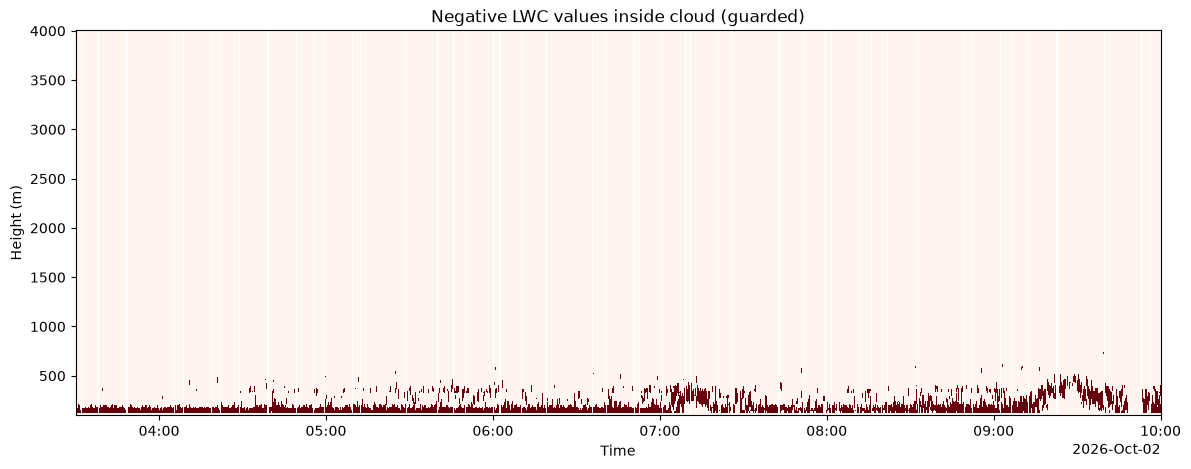

In [14]:
negative_lwc = (lwc_guarded < 0) & ds_retrieval["common_mask"]

plt.figure(figsize=(14, 5))
nan_gaps(negative_lwc.astype(int)).plot(x="Time", y="range", cmap="Reds", add_colorbar=False)
plt.title("Negative LWC values inside cloud (guarded)")
plt.xlabel("Time"); plt.ylabel("Height (m)")
plt.show()


 ### 4b. LWC map (main output)

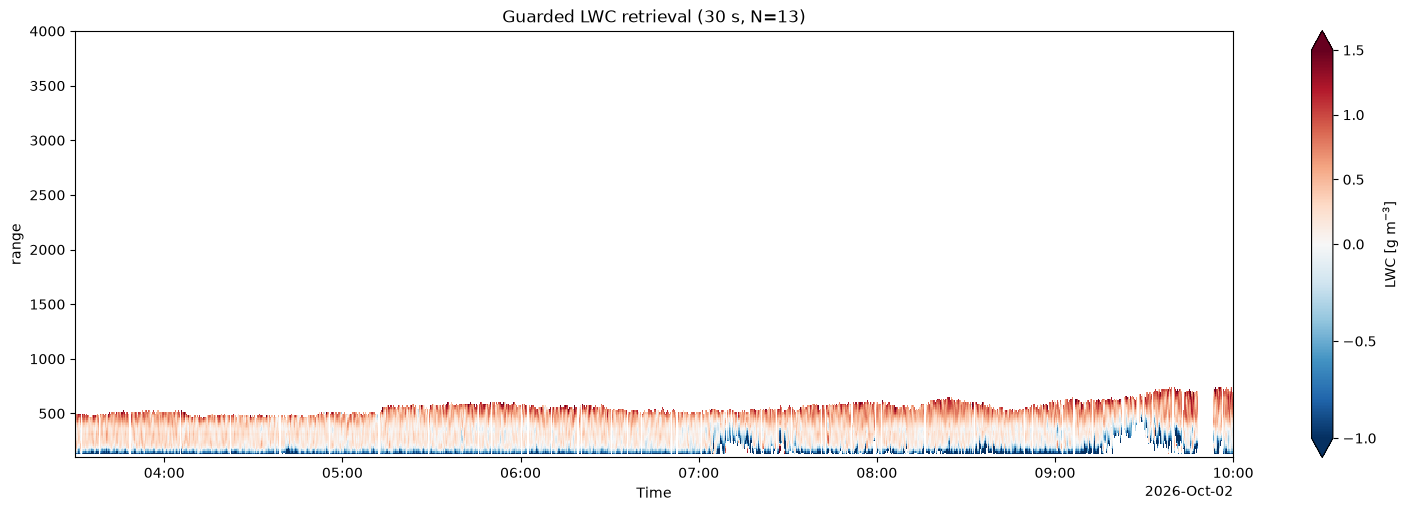

In [15]:
from matplotlib.colors import TwoSlopeNorm
fig, ax = plt.subplots(figsize=(14, 5), constrained_layout=True)
nan_gaps(lwc_guarded.where(ds_retrieval["common_mask"])).plot(
    x="Time", y="range", ax=ax, cmap="RdBu_r",
    norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1.5),
    cbar_kwargs={"label": "LWC [g m$^{-3}$]"})
ax.set_title(f"Guarded LWC retrieval (30 s, N={N_DEFAULT})")
plt.show()


 ### 4c. Two supporting graphs: LWC distribution + negative-gradient locations

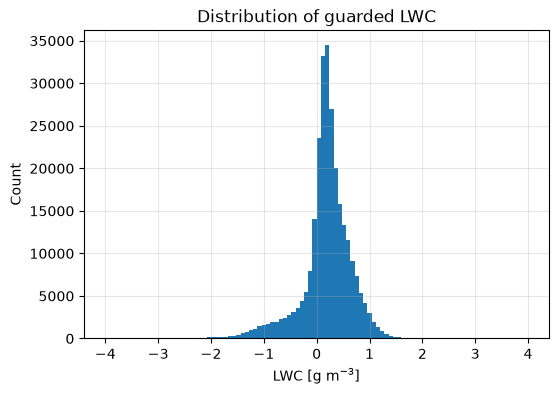

In [16]:
vals = lwc_guarded.where(ds_retrieval["common_mask"]).values
vals = vals[np.isfinite(vals)]

plt.figure(figsize=(6, 4))
plt.hist(vals, bins=100, range=(-4, 4))
plt.xlabel("LWC [g m$^{-3}$]")
plt.ylabel("Count")
plt.title("Distribution of guarded LWC")
plt.grid(alpha=0.3)
plt.show()


 ================================================================================================================================================================================================

 ## 5. LWP — kept only for later comparison (general chart, closure scatter, 3-profile spot check)

 ================================================================================================================================================================================================

 ### 5a. General LWP chart

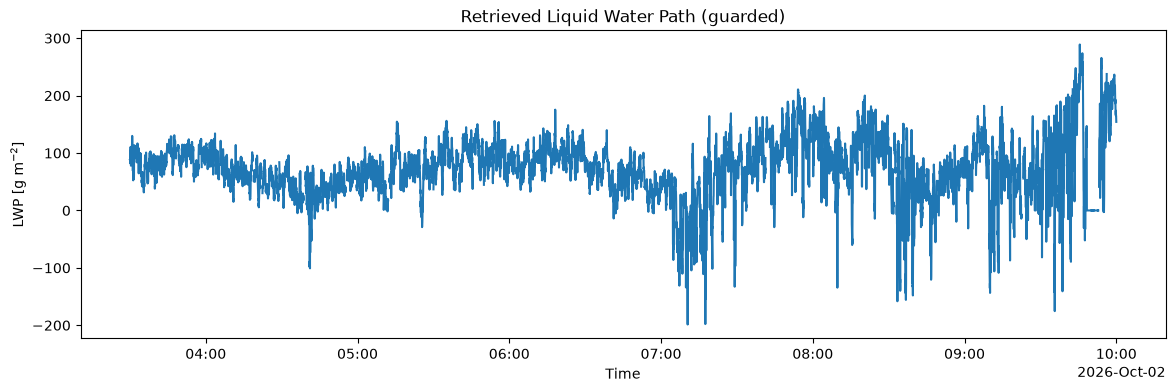

In [17]:
dz = xr.DataArray(np.gradient(dwr_2km_filt["range"].values),
                  dims="range", coords={"range": dwr_2km_filt["range"]})
lwp_guarded = (lwc_guarded.where(ds_retrieval["common_mask"]).fillna(0) * dz).sum(dim="range")
lwp_guarded = lwp_guarded.where(ds_retrieval["common_mask"].any(dim="range"))
lwp_guarded.attrs["units"] = "g m-2"

fig, ax = plt.subplots(figsize=(14, 4))
nan_gaps(lwp_guarded).plot(ax=ax)
ax.set_title("Retrieved Liquid Water Path (guarded)")
ax.set_ylabel("LWP [g m$^{-2}$]")
ax.set_xlabel("Time")
plt.show()


 ### 5b. LWP closure test (scatter vs MWR)

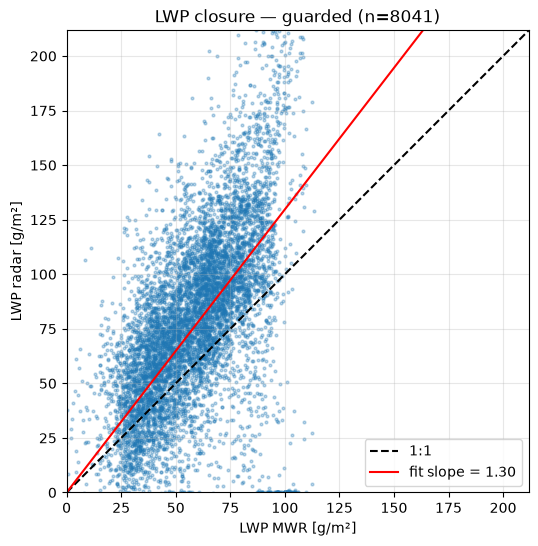

Slope through origin: 1.30   (want ~1.0)
Correlation:          0.59   (want > 0.7)
Bias:  radar - MWR = +15.9 g/m²


In [18]:
x = ds_retrieval["LWP"].values
y = lwp_guarded.values
good = np.isfinite(x) & np.isfinite(y)    # ignore near-zero MWR

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(x[good], y[good], s=4, alpha=0.3)
lim = max(np.nanpercentile(x[good], 99), np.nanpercentile(y[good], 99))
ax.plot([0, lim], [0, lim], "k--", label="1:1")
slope = np.nansum(x[good] * y[good]) / np.nansum(x[good] ** 2)
ax.plot([0, lim], [0, slope * lim], "r-", label=f"fit slope = {slope:.2f}")
ax.set_xlabel("LWP MWR [g/m²]"); ax.set_ylabel("LWP radar [g/m²]")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend()
ax.set_title(f"LWP closure — guarded (n={good.sum()})")
plt.show()

corr = np.corrcoef(x[good], y[good])[0, 1]
print(f"Slope through origin: {slope:.2f}   (want ~1.0)")
print(f"Correlation:          {corr:.2f}   (want > 0.7)")
print(f"Bias:  radar - MWR = {np.nanmean(y[good] - x[good]):+.1f} g/m²")


profiles with HATPRO LWP > -1000 g m-2: 8043 | without any retrieved gate (not in the closure): 0.0 %
n 8041  bias +34.4 %  RMSE 45.6 g m-2  r 0.59  slope 1.30


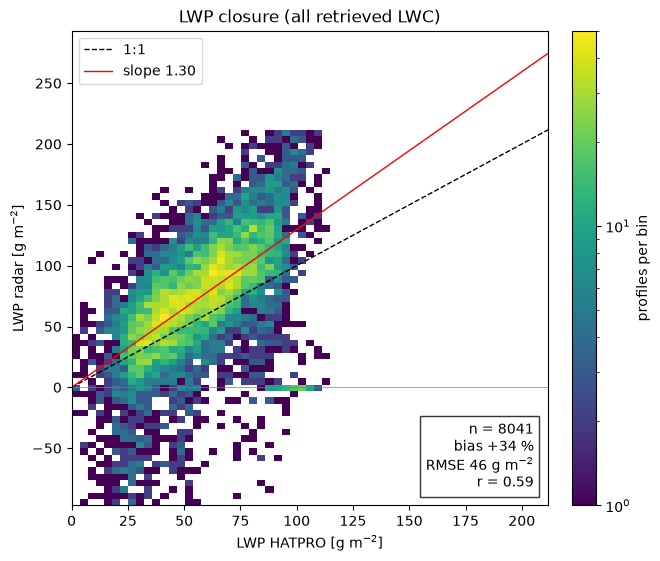

In [19]:
# =====================================================================================
# 5b. LWP CLOSURE vs HATPRO - 2-D histogram; ONE set of rules for every closure number
# =====================================================================================
from matplotlib.colors import LogNorm

MIN_MWR = - 1000    # g m-2: below this the HATPRO LWP is about as large as its own uncertainty

lwp_hat = ds_retrieval["LWP"]
lwp_all = lwp_guarded

def closure_stats(lwp_radar, lwp_mwr, min_mwr=MIN_MWR):
    """Same rules everywhere: both finite, MWR > min_mwr. Profiles without any retrieved gate are NaN -> out."""
    x, y = np.asarray(lwp_mwr, float), np.asarray(lwp_radar, float)
    ok = np.isfinite(x) & np.isfinite(y) & (x > min_mwr)
    x, y = x[ok], y[ok]
    return {"n": ok.sum(), "x": x, "y": y,
            "bias": np.median(100 * (y - x) / x),          # median relative bias [%]
            "rmse": np.sqrt(np.mean((y - x) ** 2)),
            "r": np.corrcoef(x, y)[0, 1],
            "slope": np.sum(x * y) / np.sum(x ** 2)}       # least-squares slope through the origin

s = closure_stats(lwp_all, lwp_hat)

mwr_cloudy = lwp_hat > MIN_MWR
no_retr    = mwr_cloudy & lwp_all.isnull()
print(f"profiles with HATPRO LWP > {MIN_MWR:.0f} g m-2: {int(mwr_cloudy.sum())} | "
      f"without any retrieved gate (not in the closure): {100 * float(no_retr.sum() / mwr_cloudy.sum()):.1f} %")
print(f"n {s['n']}  bias {s['bias']:+.1f} %  RMSE {s['rmse']:.1f} g m-2  r {s['r']:.2f}  slope {s['slope']:.2f}")

lim    = np.percentile(np.r_[s["x"], s["y"]], 99.5)
bins_x = np.linspace(0, lim, 60)
bins_y = np.linspace(min(0.0, np.percentile(s["y"], 0.5)), lim, 60)

fig, ax = plt.subplots(figsize=(6.5, 5.5), constrained_layout=True)
*_, im = ax.hist2d(s["x"], s["y"], bins=[bins_x, bins_y], cmin=1, norm=LogNorm(vmin=1), cmap="viridis")
ax.plot([0, lim], [0, lim], "k--", lw=1, label="1:1")
ax.plot([0, lim], [0, s["slope"] * lim], "r-", lw=1, label=f"slope {s['slope']:.2f}")
ax.axhline(0, color="grey", lw=0.5)
ax.text(0.97, 0.03, f"n = {s['n']}\nbias {s['bias']:+.0f} %\nRMSE {s['rmse']:.0f} g m$^{{-2}}$\nr = {s['r']:.2f}",
        transform=ax.transAxes, ha="right", va="bottom", bbox=dict(fc="white", alpha=0.8))
ax.set_title("LWP closure (all retrieved LWC)")
ax.set_xlabel("LWP HATPRO [g m$^{-2}$]"); ax.set_ylabel("LWP radar [g m$^{-2}$]")
ax.legend(loc="upper left")
fig.colorbar(im, ax=ax, label="profiles per bin")
plt.show()

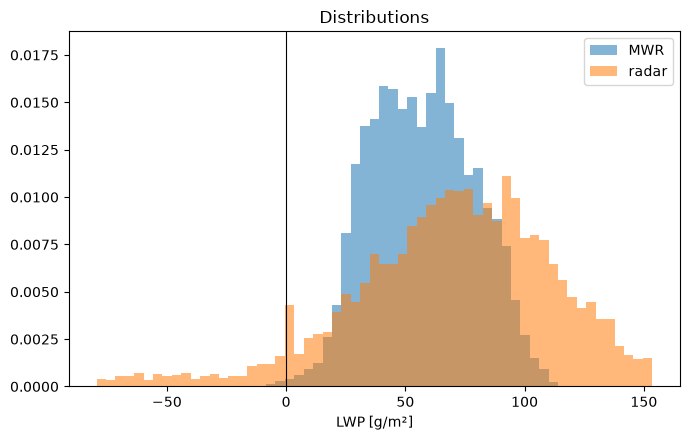

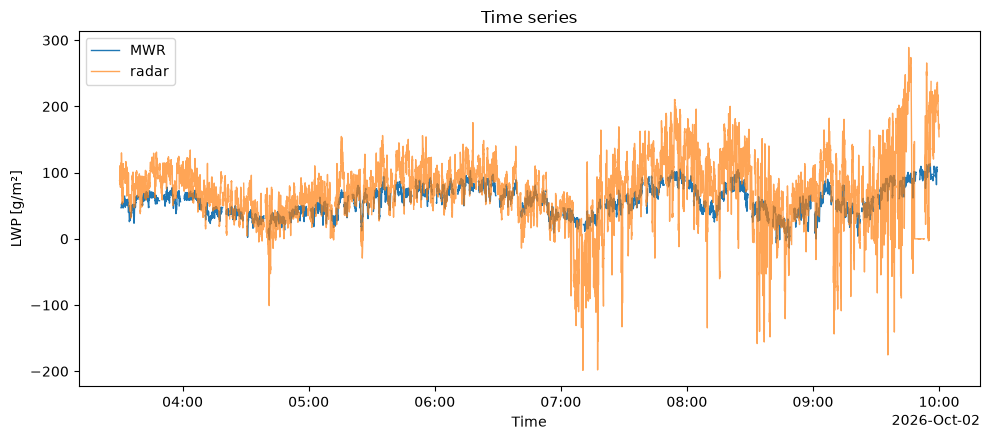

MWR   : mean   +57.0 std   21.6 p05   +24.4 p50   +56.6 p95   +92.6
radar : mean   +73.0 std   51.8 p05    -9.6 p50   +74.6 p95  +151.7


In [20]:
# %% Distribution comparison, not just scatter
x = ds_retrieval["LWP"].values
y = lwp_guarded.values
good = np.isfinite(x) & np.isfinite(y) 

bins = np.linspace(min(np.nanpercentile(y[good], 1), 0), np.nanpercentile(x[good], 99) * 1.5, 60)

# %% Plot 1: Verteilungen (Histogramm)
plt.figure(figsize=(7, 4.5))
plt.hist(x[good], bins=bins, alpha=0.55, label="MWR", density=True)
plt.hist(y[good], bins=bins, alpha=0.55, label="radar", density=True)
plt.axvline(0, color="k", lw=0.8); plt.legend()
plt.xlabel("LWP [g/m²]"); plt.title("Distributions")
plt.tight_layout(); plt.show()

# %% Plot 2: Zeitreihe
fig, ax = plt.subplots(figsize=(10, 4.5))
nan_gaps(ds_retrieval["LWP"]).plot(ax=ax, label="MWR", lw=1)
nan_gaps(lwp_guarded).plot(ax=ax, label="radar", lw=1, alpha=0.7)
ax.legend(); ax.set_ylabel("LWP [g/m²]"); ax.set_title("Time series")
plt.tight_layout(); plt.show()

# %% Statistik
for nm, v in [("MWR", x[good]), ("radar", y[good])]:
    print(f"{nm:6s}: mean {v.mean():+7.1f} std {v.std():6.1f} "
          f"p05 {np.percentile(v,5):+7.1f} p50 {np.percentile(v,50):+7.1f} p95 {np.percentile(v,95):+7.1f}")

In [21]:
# %% Export Zhu retrieval outputs for notebook 06
from pathlib import Path
import xarray as xr

ds_output_zhu = xr.Dataset(
    {
        "lwc_guarded":  lwc_guarded.rename("lwc_guarded"),
        "n_windows":    n_windows.rename("n_windows"),
        "dwr_filtered": dwr_2km_filt.rename("dwr_filtered"),
        "m_eff": m_eff.rename("m_eff"),
        "derivative_guarded": derivative_guarded.rename("derivative_guarded"),
        "n_used": n_used.rename("n_used")
        
    },
    attrs={
        "description": "Zhu et al. (2019) guarded retrieval output",
        "N_default": 13,                    # was 9
        "max_ddwr_dh": 30.0,                # add
        "max_window_std": 1.0,              # add
        "edge_pad_bottom": 2,               # add
        "edge_pad_top": 1,                  # add
        "input_dwr": "30 s averaged, 1 dB despiked",
        "mask_used": "common_mask",
        "created_by": "04_zhu_guarded_retrieval_CLEANED.ipynb",
    },
)

out_path = Path(f"../data/processed/{Processed_Dataset}/retrieval_output_zhu.nc")
out_path.parent.mkdir(parents=True, exist_ok=True)
ds_output_zhu.to_netcdf(out_path)
print(f"Saved → {out_path}")

Saved → ..\data\processed\20261002_pallas_interpolation_CLARA\retrieval_output_zhu.nc


## Comparison retrieval EDGE Gates removed before or after retrieval

In [22]:
MIN_MWR = 5.0    # g m-2, same as your closure scatter

def closure_stats(lwp_radar, lwp_mwr, min_mwr=MIN_MWR):
    """LWP closure numbers: only profiles where both are finite and MWR > min_mwr."""
    x, y = np.asarray(lwp_mwr, float), np.asarray(lwp_radar, float)
    ok = np.isfinite(x) & np.isfinite(y) & (x > min_mwr)
    x, y = x[ok], y[ok]
    return {"n": ok.sum(), "x": x, "y": y,
            "bias": np.median(100 * (y - x) / x),          # median relative bias [%]
            "rmse": np.sqrt(np.mean((y - x) ** 2)),
            "r": np.corrcoef(x, y)[0, 1],
            "slope": np.sum(x * y) / np.sum(x ** 2)}       # slope through the origin, as in your scatter

In [23]:
# =====================================================================================
# EDGE GATES: removed BEFORE the fit (current zhu.py) vs AFTER the fit   (meeting to-do B6)
#   before: pad gates never enter a window -> their DWR cannot affect any other gate
#   after : fit the full cloud, then delete the same gates -> their DWR still enters the
#           windows of the gates up to N-1 away, but gates near the edge get more windows
# =====================================================================================
PB, PT = 2, 1
TR   = lambda a: a.transpose("Time", "range")
cm   = TR(ds_retrieval["common_mask"]).fillna(0).astype(bool)
args = dict(dwr=TR(dwr_2km_filt), kappa_w=TR(ds_retrieval["kappa_W"]), kappa_ka=TR(ds_retrieval["kappa_Ka"]),
            alpha_w=TR(ds_retrieval["alpha_W"]), alpha_ka=TR(ds_retrieval["alpha_Ka"]), cloud_mask=cm,
            N_default=13, min_cloud_gates=3, max_ddwr_dh=30.0, max_window_std=1.0)

lwc_before, *_ = retrieve_lwc_zhu(**args, edge_pad_bottom=PB, edge_pad_top=PT)   # as now
lwc_full,   *_ = retrieve_lwc_zhu(**args, edge_pad_bottom=0,  edge_pad_top=0)    # full cloud

# delete exactly the gates zhu.py skips: PB above the lowest and PT below the highest cloud gate
mk   = cm.values
j    = np.arange(mk.shape[1])[None, :]
base = np.argmax(mk, axis=1)[:, None]                                  # = cloud_idx.min() in zhu.py
top  = (mk.shape[1] - 1 - np.argmax(mk[:, ::-1], axis=1))[:, None]     # = cloud_idx.max()
keep = mk.any(axis=1)[:, None] & (j >= base + PB) & (j <= top - PT)
lwc_after = lwc_full.where(keep)

A, B = lwc_before.values, lwc_after.values
both = np.isfinite(A) & np.isfinite(B)
print(f"retrieved gates: before {np.isfinite(A).sum()} | after {np.isfinite(B).sum()} | in both {both.sum()}")
for name, X in (("before", A), ("after", B)):
    v = X[both]
    print(f"  {name:>6} (same gates): median {np.median(v):.3f}  std {v.std():.3f}  negative {np.mean(v < 0):.0%}")

print("\nby distance from the cloud edge (k = 0 is the edge gate itself)")
print(f"{'edge':>5}{'k':>3}{'n':>8} | {'median':>7}{'std':>7}{'<0':>5} before | {'median':>7}{'std':>7}{'<0':>5} after")
for edge, pos, k0 in (("base", j - base, PB), ("top", top - j, PT)):
    for k in range(k0, k0 + 6):
        s = both & (pos == k)
        if s.sum() < 30:
            continue
        a, b = A[s], B[s]
        print(f"{edge:>5}{k:>3}{s.sum():>8} | {np.median(a):>7.3f}{a.std():>7.3f}{np.mean(a < 0):>5.0%}        "
              f"| {np.median(b):>7.3f}{b.std():>7.3f}{np.mean(b < 0):>5.0%}")

dz_r   = xr.DataArray(np.gradient(dwr_2km_filt["range"].values), dims="range", coords={"range": dwr_2km_filt["range"]})
lwp_of = lambda L: (L.fillna(0) * dz_r).sum("range").where(L.notnull().any("range"))
lwp_b, lwp_a = lwp_of(lwc_before), lwp_of(lwc_after)
same = lwp_b.notnull() & lwp_a.notnull()
print(f"\nLWP closure vs HATPRO (same profiles, HATPRO > {MIN_MWR:.0f} g m-2)")
for name, l in (("before", lwp_b), ("after", lwp_a)):
    s = closure_stats(l.where(same), ds_retrieval["LWP"])
    print(f"  {name:>6}: n {s['n']}  bias {s['bias']:+.1f} %  RMSE {s['rmse']:.1f}  r {s['r']:.2f}  slope {s['slope']:.2f}")

retrieved gates: before 274724 | after 274817 | in both 274724
  before (same gates): median 0.203  std 0.503  negative 22%
   after (same gates): median 0.231  std 0.622  negative 24%

by distance from the cloud edge (k = 0 is the edge gate itself)
 edge  k       n |  median    std   <0 before |  median    std   <0 after
 base  2    8647 |  -1.054  0.589  98%        |  -1.786  0.500  99%
 base  3    9011 |  -0.639  0.563  97%        |  -1.202  0.468  99%
 base  4    9149 |  -0.332  0.483  92%        |  -0.752  0.396  98%
 base  5    9252 |  -0.130  0.424  73%        |  -0.423  0.362  96%
 base  6    9314 |   0.001  0.356  50%        |  -0.187  0.313  88%
 base  7    9417 |   0.073  0.361  34%        |  -0.024  0.339  56%
  top  1    9726 |   0.799  0.354   1%        |   0.912  0.372   0%
  top  2    9741 |   0.721  0.310   1%        |   0.795  0.300   0%
  top  3    9743 |   0.657  0.276   1%        |   0.708  0.258   0%
  top  4    9744 |   0.605  0.252   1%        |   0.637  0.234  

In [24]:
lwc_cloud = lwc_guarded.where(ds_retrieval["common_mask"])
lwp_noneg = (lwc_cloud.clip(min=0).fillna(0) * dz).sum("range").where(lwc_cloud.notnull().any("range"))
ok = np.isfinite(lwp_guarded) & np.isfinite(lwp_noneg) & (lwp_guarded > 0)
print(f"LWP with negatives set to 0: median +{float(((lwp_noneg - lwp_guarded) / lwp_guarded).where(ok).median())*100:.0f} % higher")

LWP with negatives set to 0: median +44 % higher


## Comparison of different number of Gates N

In [26]:
# Interior per-gate DWR noise of THIS day: adjacent-gate differences, away from cloud base/top
TR   = lambda a: a.transpose("Time", "range")
dwr  = TR(dwr_2km_filt).values                                   # the DWR that goes into the fit
mk   = TR(ds_retrieval["common_mask"]).fillna(0).astype(bool).values
j    = np.arange(mk.shape[1])[None, :]
base = np.argmax(mk, axis=1)[:, None]
top  = (mk.shape[1] - 1 - np.argmax(mk[:, ::-1], axis=1))[:, None]

EDGE = 3                                                         # interior = at least 3 gates from base and top
interior = mk & (j >= base + EDGE) & (j <= top - EDGE)
d = np.diff(np.where(interior, dwr, np.nan), axis=1)             # NaN unless both gates are interior
d = d[np.isfinite(d)]

SIG_DWR_DB = float(d.std() / np.sqrt(2))                         # difference of 2 gates has variance 2*sigma^2
robust     = float(1.4826 * np.median(np.abs(d - np.median(d))) / np.sqrt(2))
print(f"interior sigma_DWR = {SIG_DWR_DB:.3f} dB  (robust MAD estimate {robust:.3f} dB, n = {d.size})")

interior sigma_DWR = 0.167 dB  (robust MAD estimate 0.064 dB, n = 238802)


In [27]:
# =====================================================================
# WINDOW-SIZE SWEEP — two rounds: no padding, and (bottom=2, top=1) cell 46
# =====================================================================
N_VALUES = [5, 7, 9, 11, 13, 17, 21]
PAD_SETS = [(0, 0), (2, 1)]
MAX_DDWR = 30.0
      

# The window std is signal + noise in quadrature. The signal part grows with
# the window span (so with N), the noise part doesn't. Scale accordingly,
# calibrated so threshold(N=13) = 1.0 dB, i.e. your production value.
K_SIGNAL = np.sqrt(max(1.0**2 - SIG_DWR_DB**2, 0.0)) / 13.0

STD_MODE = "scaled"         # "scaled" | "fixed" (1.0 for all N) | "off"

def std_threshold(N):
    if STD_MODE == "off":   return 1e9
    if STD_MODE == "fixed": return 1.0
    return float(np.sqrt((K_SIGNAL * N) ** 2 + SIG_DWR_DB ** 2))

cmask = ds_retrieval["common_mask"].transpose("Time", "range")
dz    = np.gradient(dwr_2km_filt["range"].values)
dr_m  = float(np.median(np.diff(dwr_2km_filt["range"].values)))
dk    = float((ds_retrieval["kappa_W"] - ds_retrieval["kappa_Ka"])
              .where(cmask).median())

assert dwr_2km_filt.transpose("Time", "range").shape == cmask.shape, \
    "dwr_2km_filt is not on the mask grid - restart the kernel"

print(f"gate {dr_m:.1f} m | dkappa {dk:.2f} dB/km/(g/m3) | std mode '{STD_MODE}'")

sweep_N = {}
for pb, pt in PAD_SETS:
    for N in N_VALUES:
        thr = std_threshold(N)
        lwc, *_ = retrieve_lwc_zhu(
            dwr=dwr_2km_filt,
            kappa_w=ds_retrieval["kappa_W"],
            kappa_ka=ds_retrieval["kappa_Ka"],
            alpha_w=ds_retrieval["alpha_W"],
            alpha_ka=ds_retrieval["alpha_Ka"],
            cloud_mask=cmask,
            N_default=N, min_cloud_gates=3,
            max_ddwr_dh=MAX_DDWR, max_window_std=thr,
            edge_pad_bottom=pb, edge_pad_top=pt,
        )
        sweep_N[(pb, pt, N)] = lwc
        print(f"  pad ({pb},{pt})  N={N:>2}  span={N*dr_m:>4.0f} m  "
              f"std_thr={thr:.2f} dB  {int(np.isfinite(lwc.values).sum()):>7} gates")

gate 13.5 m | dkappa 3.62 dB/km/(g/m3) | std mode 'scaled'
  pad (0,0)  N= 5  span=  68 m  std_thr=0.41 dB   284769 gates
  pad (0,0)  N= 7  span=  95 m  std_thr=0.56 dB   289133 gates
  pad (0,0)  N= 9  span= 122 m  std_thr=0.70 dB   292541 gates
  pad (0,0)  N=11  span= 149 m  std_thr=0.85 dB   296621 gates
  pad (0,0)  N=13  span= 176 m  std_thr=1.00 dB   300135 gates
  pad (0,0)  N=17  span= 230 m  std_thr=1.30 dB   301234 gates
  pad (0,0)  N=21  span= 284 m  std_thr=1.60 dB   300964 gates
  pad (2,1)  N= 5  span=  68 m  std_thr=0.41 dB   272659 gates
  pad (2,1)  N= 7  span=  95 m  std_thr=0.56 dB   273554 gates
  pad (2,1)  N= 9  span= 122 m  std_thr=0.70 dB   274026 gates
  pad (2,1)  N=11  span= 149 m  std_thr=0.85 dB   274395 gates
  pad (2,1)  N=13  span= 176 m  std_thr=1.00 dB   274724 gates
  pad (2,1)  N=17  span= 230 m  std_thr=1.30 dB   274729 gates
  pad (2,1)  N=21  span= 284 m  std_thr=1.60 dB   273129 gates


In [ ]:
# --- compare ---
lwp_mwr = ds_retrieval["LWP"].values

def sigma_lwc_ols(N, sig_dwr, dr_m, dkappa):
    """OLS slope error through the retrieval equation. White-noise prediction."""
    if N < 3:
        return np.nan
    slope = sig_dwr * np.sqrt(12.0 / (N * (N**2 - 1))) / dr_m * 1000.0   # dB/km
    return 0.5 * slope / dkappa

def diagnose_N(pb, pt):
    print(f"\n=== edge pads (bottom={pb}, top={pt}) ===")
    print(f"{'N':>4}{'span':>6}{'gates':>9}{'prof':>7}{'median':>8}{'std':>7}"
          f"{'pred':>7}{'ratio':>7}{'<0':>6}{'<-1':>7}{'<-2':>7}"
          f" | {'LWPbias%':>9}{'rmse':>7}{'corr':>6}")
    for N in N_VALUES:
        L = sweep_N[(pb, pt, N)].where(cmask).values
        v = L[np.isfinite(L)]
        if v.size < 100:
            print(f"{N:>4}   too few gates ({v.size})")
            continue

        lwp_r = np.nansum(np.where(np.isfinite(L), L, 0.0) * dz, axis=1)
        lwp_r[~np.isfinite(L).any(axis=1)] = np.nan
        ok = np.isfinite(lwp_mwr) & np.isfinite(lwp_r) & (lwp_mwr > 5)

        if ok.sum() >= 30:
            bias = np.median(100 * (lwp_r[ok] - lwp_mwr[ok]) / lwp_mwr[ok])
            rmse = np.sqrt(np.mean((lwp_r[ok] - lwp_mwr[ok]) ** 2))
            corr = np.corrcoef(lwp_r[ok], lwp_mwr[ok])[0, 1]
        else:
            bias = rmse = corr = np.nan

        pred  = sigma_lwc_ols(N, SIG_DWR_DB, dr_m, dk)
        nprof = int(np.isfinite(L).any(axis=1).sum())

        print(f"{N:>4}{N*dr_m:>6.0f}{v.size:>9}{nprof:>7}{np.median(v):>8.3f}"
              f"{v.std():>7.3f}{pred:>7.3f}{v.std()/pred:>7.2f}"
              f"{(v < 0).mean():>6.0%}{(v < -1).mean():>7.1%}{(v < -2).mean():>7.1%}"
              f" | {bias:>9.1f}{rmse:>7.1f}{corr:>6.2f}")

for pb, pt in PAD_SETS:
    diagnose_N(pb, pt)


=== edge pads (bottom=0, top=0) ===
   N  span    gates   prof  median    std   pred  ratio    <0    <-1    <-2 |  LWPbias%   rmse  corr
   5    68   284769   9778   0.240  1.007  0.539   1.87   34%   9.4%   4.8% |      -5.4   62.5  0.51
   7    95   289133   9777   0.251  0.988  0.322   3.06   29%   9.8%   5.2% |     -30.4   63.8  0.53
   9   122   292541   9774   0.250  0.947  0.220   4.30   27%  10.0%   5.3% |     -50.0   61.8  0.56
  11   149   296621   9760   0.238  0.960  0.163   5.90   27%  10.7%   5.8% |     -79.7   76.1  0.48
  13   176   300135   9758   0.223  0.936  0.126   7.40   27%  11.3%   5.7% |    -109.4   76.9  0.53
  17   230   301234   9731   0.205  0.750  0.084   8.88   31%   9.5%   3.3% |     -67.8   60.1  0.58
  21   284   300964   9675   0.202  0.647  0.061  10.52   35%   7.5%   1.0% |     -38.3   55.3  0.56

=== edge pads (bottom=2, top=1) ===
   N  span    gates   prof  median    std   pred  ratio    <0    <-1    <-2 |  LWPbias%   rmse  corr
   5    68   2726

## Edge Pad analysis

In [29]:
# --- pad sweep ---
PADS      = [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2) , (3, 1), (4, 1), (5, 1), (6, 1), (4, 2), (5, 2), (6, 2)]
N_DEFAULT = 13
cmask     = ds_retrieval["common_mask"].transpose("Time", "range")

assert dwr_2km_filt.transpose("Time", "range").shape == cmask.shape, \
    "dwr_2km_filt is not on the mask grid - a later cell overwrote it; restart the kernel"

sweep_pad = {}
for pb, pt in PADS:
    lwc, *_ = retrieve_lwc_zhu(
        dwr=dwr_2km_filt,
        kappa_w=ds_retrieval["kappa_W"],
        kappa_ka=ds_retrieval["kappa_Ka"],
        alpha_w=ds_retrieval["alpha_W"],
        alpha_ka=ds_retrieval["alpha_Ka"],
        cloud_mask=cmask,
        N_default=N_DEFAULT, min_cloud_gates=3,
        max_ddwr_dh=30.0, max_window_std=1.0,
        edge_pad_bottom=pb, edge_pad_top=pt,
    )
    sweep_pad[(pb, pt)] = lwc
    print(f"  pad ({pb},{pt}): {int(np.isfinite(lwc.values).sum())} gates")


  pad (0,0): 300135 gates
  pad (1,0): 292692 gates
  pad (2,0): 284497 gates
  pad (2,1): 274724 gates
  pad (2,2): 264854 gates
  pad (3,1): 266004 gates
  pad (4,1): 256991 gates
  pad (5,1): 247873 gates
  pad (6,1): 238644 gates
  pad (4,2): 247145 gates
  pad (5,2): 238039 gates
  pad (6,2): 228810 gates


In [ ]:

# --- compare ---
dz       = np.gradient(dwr_2km_filt["range"].values)
lwp_mwr  = ds_retrieval["LWP"].values

base     = sweep_pad[PADS[0]].where(cmask).values
base_n   = max(int(np.isfinite(base).sum()), 1)
base_lwp = np.nansum(np.where(np.isfinite(base), base, 0.0) * dz, axis=1)
base_lwp[~np.isfinite(base).any(axis=1)] = np.nan

print(f"{'pad(b,t)':>9}{'gates':>9}{'keep%':>7}{'median':>8}{'std':>7}{'<0':>6}"
      f" | {'LWPbias%':>9}{'LWPrmse':>9}{'corr':>6}{'vs(0,0)%':>10}")
for k in PADS:
    L = sweep_pad[k].where(cmask).values
    v = L[np.isfinite(L)]
    lwp_r = np.nansum(np.where(np.isfinite(L), L, 0.0) * dz, axis=1)
    lwp_r[~np.isfinite(L).any(axis=1)] = np.nan

    ok = np.isfinite(lwp_mwr) & np.isfinite(lwp_r) & (lwp_mwr > 5)
    if v.size == 0 or ok.sum() < 30:
        print(f"{str(k):>9}  too few valid gates/profiles - skipped")
        continue

    bias = np.median(100*(lwp_r[ok] - lwp_mwr[ok]) / lwp_mwr[ok])
    rmse = np.sqrt(np.mean((lwp_r[ok] - lwp_mwr[ok])**2))
    corr = np.corrcoef(lwp_r[ok], lwp_mwr[ok])[0, 1]
    ok2  = ok & np.isfinite(base_lwp) & (base_lwp > 0)
    rel  = np.median(100*(lwp_r[ok2] - base_lwp[ok2]) / base_lwp[ok2])

    print(f"{str(k):>9}{v.size:>9}{100*v.size/base_n:>7.1f}{np.median(v):>8.3f}"
          f"{v.std():>7.3f}{(v < 0).mean():>6.0%} | {bias:>9.1f}{rmse:>9.1f}"
          f"{corr:>6.2f}{rel:>10.1f}")

 pad(b,t)    gates  keep%  median    std    <0 |  LWPbias%  LWPrmse  corr  vs(0,0)%
   (0, 0)   300135  100.0   0.223  0.936   27% |    -109.4     76.9  0.53       0.0
   (1, 0)   292692   97.5   0.216  0.704   25% |      -4.3     45.1  0.61      67.7
   (2, 0)   284497   94.8   0.215  0.545   21% |      71.5     59.1  0.61     165.7
   (2, 1)   274724   91.5   0.203  0.503   22% |      35.1     44.8  0.61     105.2
   (2, 2)   264854   88.2   0.191  0.493   23% |      12.6     40.7  0.61      73.5
   (3, 1)   266004   88.6   0.219  0.416   18% |      77.2     58.9  0.61     163.9
   (4, 1)   256991   85.6   0.245  0.377   14% |      99.9     67.9  0.63     192.7
   (5, 1)   247873   82.6   0.262  0.367   12% |     104.4     69.8  0.64     200.6
   (6, 1)   238644   79.5   0.267  0.364   13% |      99.3     67.3  0.64     192.1
   (4, 2)   247145   82.3   0.231  0.365   14% |      78.1     57.6  0.62     158.0
   (5, 2)   238039   79.3   0.245  0.354   13% |      81.9     59.3  0.63   

In [31]:
# ===== EXPORT sensitivity results (notebook 04: N sweep + pad sweep) =====
import pandas as pd

def sweep_stats(lwc, mask, lwp_mwr, dz):
    """One row of numbers for one setting. keep% is relative to ALL common-mask gates,
    so every test and every day uses the same reference."""
    m = mask.transpose("Time", "range").fillna(0).astype(bool)
    L = lwc.transpose("Time", "range").where(m).values
    v = L[np.isfinite(L)]
    lwp_r = np.nansum(np.where(np.isfinite(L), L, 0.0) * dz, axis=1)
    lwp_r[~np.isfinite(L).any(axis=1)] = np.nan
    ok = np.isfinite(lwp_mwr) & np.isfinite(lwp_r)            # all MWR values, absolute bias
    return {"gates": v.size, "keep_pct": 100 * v.size / int(m.values.sum()),
            "median": np.median(v), "std": v.std(),
            "neg_pct": 100 * np.mean(v < 0), "abs_gt2_pct": 100 * np.mean(np.abs(v) > 2),
            "lwp_bias": np.mean(lwp_r[ok] - lwp_mwr[ok]),
            "lwp_rmse": np.sqrt(np.mean((lwp_r[ok] - lwp_mwr[ok]) ** 2)),
            "lwp_corr": np.corrcoef(lwp_r[ok], lwp_mwr[ok])[0, 1], "n_prof": int(ok.sum())}

mask_e  = ds_retrieval["common_mask"]
lwp_e   = ds_retrieval["LWP"].values
dz_e    = np.gradient(dwr_2km_filt["range"].values)
rows = []
for (pb, pt, N), lwc in sweep_N.items():
    rows.append({"day": Processed_Dataset, "test": f"N, pads ({pb},{pt})", "setting": N,
                 **sweep_stats(lwc, mask_e, lwp_e, dz_e)})
for (pb, pt), lwc in sweep_pad.items():
    rows.append({"day": Processed_Dataset, "test": "edge pads", "setting": f"({pb},{pt})",
                 **sweep_stats(lwc, mask_e, lwp_e, dz_e)})

out = Path(f"../data/processed/{Processed_Dataset}/sensitivity_04.csv")
pd.DataFrame(rows).to_csv(out, index=False)
print(f"saved {len(rows)} rows -> {out}")

saved 26 rows -> ..\data\processed\20261002_pallas_interpolation_CLARA\sensitivity_04.csv
